# Calibration and retraining data

Both Minitron papers draw their calibration set from the same blend used for
retraining (Section 2.2 / "Dataset" in 2408.11796) -- a random slice of
1024 samples is enough to drive the activation statistics importance
estimation needs. This project draws both from
`bigcode/the-stack-dedup/data/typescript`.

`configs/qwen3-30b-a3b.toml` already pins the split: shard 0 of 71 for
calibration, the remaining 70 for retraining. Shard-level, not row-level --
two shards never share a row, so the two pools are disjoint by construction.
This notebook pulls real data through that config and checks the claim
empirically rather than just trusting the construction: real samples, their
token-length distribution, and a `hexsha`-keyed confirmation that nothing
leaked across the split.

In [1]:
from bonsai.config import load_config
from bonsai.data import load_samples, tokenize_samples, verify_disjoint

data = load_config("../configs/qwen3-30b-a3b.toml").data
print(f"calibration shards: {len(data.calibration_shards)}")
print(f"retraining shards:  {len(data.retraining_shards)}")
print(f"calibration_samples: {data.calibration_samples}")

calibration shards: 1
retraining shards:  70
calibration_samples: 1024


## Pulling the samples

Calibration pulls the full 1024-sample count from its one reserved shard.
The retraining side only needs enough of a peek to compare against and to
run the disjointness check -- streaming across all 70 retraining shards
costs a fixed per-file resolution before any row comes back, so `shard_limit`
caps this to the first few rather than paying that cost 70 times over for a
sanity check. A real retraining run (Phase 3/4) omits `shard_limit` and uses
the whole pool.

In [2]:
calibration = load_samples(data, "calibration", n=data.calibration_samples, seed=0)
retraining_peek = load_samples(
    data, "retraining", n=data.calibration_samples, shard_limit=3, seed=1
)

len(calibration), len(retraining_peek)

(1024, 1024)

## What's actually in there

A few raw calibration samples -- source repo, file path, and the first
couple of lines -- as evidence this is real TypeScript, not a schema fixture.

In [3]:
for sample in calibration[:3]:
    print(f"{sample['max_stars_repo_name']}:{sample['max_stars_repo_path']}")
    print("  " + "\n  ".join(sample["content"].splitlines()[:3]))
    print()

senad-zaimovic/ews-javascript-api:src/js/PropertyDefinitions/ByteArrayPropertyDefinition.ts
  ﻿import {PropertyBag} from "../Core/PropertyBag";
  import {ExchangeService} from "../Core/ExchangeService";
  import {EwsLogging} from "../Core/EwsLogging";

endeavourhealth-discovery/Angular8:projects/dds-angular8/layout/src/public_api.ts
  /*
   * Public API Surface of dds-angular8
   */

andreasgl/ioBroker.yahka:src/shared/yahka.utils.ts
  
  export function propertyExists<T>(object: any, property: keyof T) {
      return property in object;



## Token-length distribution

Tokenized with the actual target model's tokenizer, truncated at
`tokenize_samples`'s default `max_length=2048` -- a pipeline default for this
step, not a commitment to the calibration sequence length Phase 2 actually
uses for importance estimation.

In [4]:
from transformers import AutoTokenizer

config = load_config("../configs/qwen3-30b-a3b.toml")
tokenizer = AutoTokenizer.from_pretrained(config.model.repo_id, revision=config.model.revision)

calibration_tok = tokenize_samples(calibration, tokenizer)
retraining_tok = tokenize_samples(retraining_peek, tokenizer)

print(f"calibration mean length: {calibration_tok.mean_length:.1f} tokens")
print(f"retraining  mean length: {retraining_tok.mean_length:.1f} tokens")

calibration mean length: 580.9 tokens
retraining  mean length: 451.1 tokens


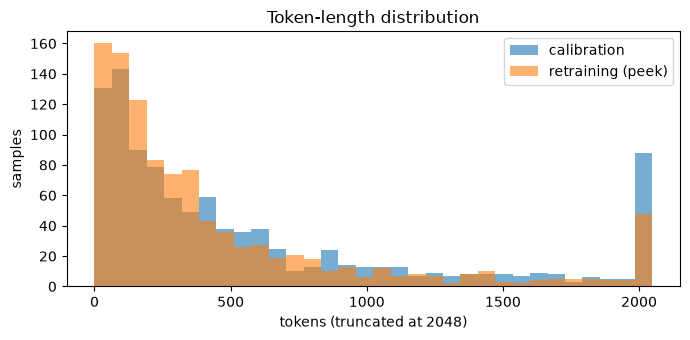

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = range(0, 2049, 64)
ax.hist(calibration_tok.lengths, bins=bins, alpha=0.6, label="calibration")
ax.hist(retraining_tok.lengths, bins=bins, alpha=0.6, label="retraining (peek)")
ax.set_xlabel("tokens (truncated at 2048)")
ax.set_ylabel("samples")
ax.set_title("Token-length distribution")
ax.legend()
fig.tight_layout()
plt.show()

## Confirming the split is actually disjoint

`hexsha` is the blob hash the-stack-dedup assigns each file; an exact
duplicate between the two pools would share it. The shard-level split
already makes this structurally impossible -- this is the empirical check,
not a substitute for it.

In [6]:
verify_disjoint(calibration, retraining_peek)

calibration_hexsha = {s["hexsha"] for s in calibration}
retraining_hexsha = {s["hexsha"] for s in retraining_peek}
print(
    f"{len(calibration_hexsha)} unique calibration files, {len(retraining_hexsha)} unique retraining files"
)
print("no overlap -- verify_disjoint did not raise")

1024 unique calibration files, 1024 unique retraining files
no overlap -- verify_disjoint did not raise
